# Proyecto 2: ¿Se puede predecir un partido?

**Fuerza deportiva, economía y el resultado de los partidos internacionales (1960–2026)**

Data Science · Sección A · Segundo semestre 2026

**Autor:** Milton Beltrán
**Dataset:** International football results 1872–2026 (martj42) + World Development Indicators (Banco Mundial) + Population estimates (ONS, Reino Unido). Los mismos datos del Proyecto 1, mejorados.

| Criterio | Pts | Qué buscamos |
|---|---|---|
| Preparación y validación | 3 | El test se toca una sola vez; nada se filtra al modelo |
| Búsqueda de opciones y ensamble | 2 | Probaron opciones con razón, no al azar |
| Métrica e interpretación | 2 | Dicen por qué esa métrica y dónde se equivoca el modelo |
| Análisis sin respuestas | 2 | Cada grupo o eje tiene nombre y descripción |
| Límites | 1 | Qué no puede concluirse |

## 1. Pregunta y datos

El Proyecto 1 encontró que el PIB per cápita explica poco del desempeño anual de una selección (R² de test 0.147) y que la población pesa casi el doble que el dinero. Este proyecto baja de país-año a **partido** y hace una pregunta más dura: si ya se sabe qué tan fuerte es cada equipo en la cancha, ¿le queda algo por decir a la economía?

**Pregunta:** Antes de que se juegue un partido internacional, ¿se puede predecir si gana el local, empatan o gana la visita? Y si ya se conoce la fuerza deportiva de cada equipo (su rating Elo), ¿saber su PIB per cápita y su población mejora la predicción?

**Para quién y qué decisión cambiaría:** Una federación que busca planificar sus próximos partidos amistosos.

**Tipo de problema:** predecir una categoría (clasificación en tres clases).

**Columna que se quiere predecir:** `resultado` ∈ {`local`, `empate`, `visita`}, con el marcador de tiempo reglamentario más prórroga. Los penales no cuentan: un partido definido por penales es un empate.

**Qué representa una fila:** un partido internacional jugado desde 1960 en el que los dos equipos tienen PIB per cápita y población reportados ese año.

**Fuente, fecha de descarga y licencia:** las mismas tres fuentes del Proyecto 1, con las copias congeladas en `data/raw/`. La ficha completa está en `data/procedencia.json`.

| | Partidos | Economía | Población del Reino Unido |
|---|---|---|---|
| **Fuente** | [martj42/international_results](https://github.com/martj42/international_results) | [API del Banco Mundial](https://data.worldbank.org) | [ONS](https://www.ons.gov.uk/peoplepopulationandcommunity/populationandmigration/populationestimates) |
| **Indicadores** | `results.csv` | `NY.GDP.PCAP.KD` (PIB per cápita, US$ constantes de 2015) y `SP.POP.TOTL` | Población a mitad de año de Inglaterra, Escocia, Gales e Irlanda del Norte |
| **Licencia** | CC0-1.0 (dominio público) | CC BY 4.0 | Open Government Licence v3.0 |
| **Fecha de descarga** | 2026-09-14 | 2026-09-14 | 2026-09-14 |

### Qué se mejoró respecto al Proyecto 1

| | Proyecto 1 | Proyecto 2 |
|---|---|---|
| **Unidad** | un país en un año | un partido |
| **Fuerza del rival** | `fuerza_rival`: promedio histórico de diferencia de goles, calculado con partidos futuros y de países de test (fuga declarada en el P1) | **Elo antes de cada partido**, calculado en orden cronológico: cada fila solo ve el pasado |
| **Validación** | partición por país, una sola vez | corte por fecha (test = partidos desde 2022) y validación cruzada temporal dentro del train |
| **Modelos** | trivial y regresión lineal | tonto, regresión logística y gradient boosting con búsqueda de opciones |

Se conserva la limpieza del P1: filtro de los 78 agregados del Banco Mundial, diccionario de 33 nombres, población del ONS con el PIB del Reino Unido para las cuatro naciones británicas y exclusión de las selecciones que no son países.

### El rating Elo

Se sigue la fórmula del [World Football Elo Ratings](https://www.eloratings.net/about). Todos los equipos arrancan en 1500 y después de cada partido intercambian puntos:

$$\text{cambio} = K \cdot G \cdot (W - W_e), \qquad W_e = \frac{1}{10^{-\Delta/400} + 1}$$

- $W$ es el resultado real (1 gana, 0.5 empata, 0 pierde) y $W_e$ el esperado según la diferencia de ratings $\Delta$, a la que se le suman 100 puntos de ventaja si el local juega en casa.
- $K$ pesa la importancia del partido: 60 Mundial, 50 torneo continental, 40 eliminatorias y Nations League, 30 otros torneos, 20 amistosos.
- $G$ premia la goleada: 1 si se gana por uno, 1.5 por dos, $(11 + N)/8$ por tres o más.

El Elo se calcula recorriendo **todos** los partidos desde 1872, para que en 1960 los ratings ya estén calentados, y cada fila guarda el rating que cada equipo tenía **antes** de jugar ese partido.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

ANCHO = 68

# encabezado de bloque, para que las salidas no se amontonen
def titulo(texto):
    print()
    print(texto)
    print("-" * ANCHO)

RANDOM_STATE = 42
RAW = Path("data/raw")

pd.set_option("display.width", 120)

In [2]:
# results.csv tal como viene: una fila por partido
def cargar_partidos():
    df = pd.read_csv(RAW / "results.csv", parse_dates=["date"])
    df["year"] = df["date"].dt.year
    return df


# un indicador del Banco Mundial, ya sin los 78 agregados
def cargar_indicador_bm(indicador, nombre):
    meta = json.loads((RAW / "wb_countries.json").read_text())[1]
    paises_reales = {c["name"] for c in meta if c["region"]["value"] != "Aggregates"}

    registros = json.loads((RAW / f"wb_{indicador}.json").read_text())[1]
    df = pd.DataFrame([
        {"wb_country": r["country"]["value"], "year": int(r["date"]), nombre: r["value"]}
        for r in registros
    ])
    return df[df["wb_country"].isin(paises_reales)].reset_index(drop=True)


# poblacion de las cuatro naciones britanicas, que el Banco Mundial no separa
def cargar_poblacion_ons():
    series = {"enpop": "England", "scpop": "Scotland",
              "wapop": "Wales", "nipop": "Northern Ireland"}
    filas = []
    for archivo, pais in series.items():
        datos = json.loads((RAW / f"ons_{archivo}.json").read_text())
        for obs in datos["years"]:
            filas.append({"team": pais, "year": int(obs["year"]),
                          "pop": float(obs["value"])})
    return pd.DataFrame(filas)


# las dos fuentes escriben distinto el mismo pais (diccionario del P1)
NOMBRES_BM = {
    "South Korea": "Korea, Rep.",          "North Korea": "Korea, Dem. People's Rep.",
    "Russia": "Russian Federation",        "Turkey": "Turkiye",
    "Ivory Coast": "Cote d'Ivoire",        "DR Congo": "Congo, Dem. Rep.",
    "Congo": "Congo, Rep.",                "Egypt": "Egypt, Arab Rep.",
    "Iran": "Iran, Islamic Rep.",          "Venezuela": "Venezuela, RB",
    "Syria": "Syrian Arab Republic",       "Yemen": "Yemen, Rep.",
    "Laos": "Lao PDR",                     "Cape Verde": "Cabo Verde",
    "Vietnam": "Viet Nam",                 "Kyrgyzstan": "Kyrgyz Republic",
    "Slovakia": "Slovak Republic",         "Czech Republic": "Czechia",
    "Gambia": "Gambia, The",               "Bahamas": "Bahamas, The",
    "Hong Kong": "Hong Kong SAR, China",   "Macau": "Macao SAR, China",
    "Brunei": "Brunei Darussalam",         "Saint Kitts and Nevis": "St. Kitts and Nevis",
    "Saint Lucia": "St. Lucia",            "Republic of Ireland": "Ireland",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "São Tomé and Príncipe": "Sao Tome and Principe",
    "Palestine": "West Bank and Gaza",     "Curaçao": "Curacao",
    "United States Virgin Islands": "Virgin Islands (U.S.)",
    "Saint Martin": "St. Martin (French part)",
    "Micronesia": "Micronesia, Fed. Sts.",
}

BRITANICAS = ["England", "Scotland", "Wales", "Northern Ireland"]

NO_PAISES = ["Ynys Môn", "Shetland", "Orkney", "Isle of Wight", "Padania", "Sápmi",
             "Frøya", "Saare County", "Western Isles", "Gotland", "Menorca",
             "Provence", "Alderney", "Åland Islands", "Jersey", "Guernsey"]


# PIB per capita y poblacion por (equipo, año), con la regla del P1 para las britanicas:
# poblacion real del ONS y PIB per capita del Reino Unido completo
def economia_por_equipo(equipos):
    eco_bm = gdppc.merge(poblacion, on=["wb_country", "year"]).dropna()

    base = pd.DataFrame({"team": sorted(set(equipos) - set(BRITANICAS))})
    base["wb_country"] = base["team"].map(NOMBRES_BM).fillna(base["team"])
    resto = base.merge(eco_bm, on="wb_country")[["team", "year", "gdppc", "pop"]]

    pib_uk = eco_bm.loc[eco_bm["wb_country"] == "United Kingdom", ["year", "gdppc"]]
    britanicas = pop_uk.merge(pib_uk, on="year")[["team", "year", "gdppc", "pop"]]

    return pd.concat([resto, britanicas], ignore_index=True)


partidos = cargar_partidos()
gdppc = cargar_indicador_bm("NY.GDP.PCAP.KD", "gdppc")
poblacion = cargar_indicador_bm("SP.POP.TOTL", "pop")
pop_uk = cargar_poblacion_ons()

titulo("FUENTES CARGADAS")
print(f"  {'partidos':<12} {partidos.shape[0]:>7,} filas  ({partidos['date'].min().date()} a {partidos['date'].max().date()})")
print(f"  {'gdppc':<12} {gdppc.shape[0]:>7,} filas  ({gdppc['wb_country'].nunique()} países)")
print(f"  {'población':<12} {poblacion.shape[0]:>7,} filas")
print(f"  {'pop_uk':<12} {pop_uk.shape[0]:>7,} filas  ({', '.join(sorted(pop_uk['team'].unique()))})")


FUENTES CARGADAS
--------------------------------------------------------------------
  partidos      49,547 filas  (1872-11-30 a 2026-08-26)
  gdppc         14,322 filas  (217 países)
  población     14,322 filas
  pop_uk           216 filas  (England, Northern Ireland, Scotland, Wales)


In [3]:
CONTINENTALES = {"Copa América", "UEFA Euro", "African Cup of Nations", "AFC Asian Cup",
                 "Gold Cup", "CONCACAF Championship", "Oceania Nations Cup",
                 "Confederations Cup"}

# las cinco categorias de torneo; el modelo y la seccion 2 usan esta misma columna
def tipo_torneo(torneo):
    if torneo == "Friendly":
        return "amistoso"
    elif torneo == "FIFA World Cup":
        return "mundial"
    elif torneo in CONTINENTALES:
        return "continental"
    elif "qualification" in torneo or "Nations League" in torneo:
        return "eliminatoria"
    else:
        return "otro"


# K del World Football Elo segun la importancia del partido
K_POR_TIPO = {"mundial": 60, "continental": 50, "eliminatoria": 40, "otro": 30, "amistoso": 20}
ELO_INICIAL = 1500
VENTAJA_LOCAL = 100


# pesa mas una goleada que un 1-0; recibe la diferencia de goles, no los goles de un equipo
def multiplicador_goles(dif):
    n = abs(dif)
    if n <= 1:
        return 1.0
    elif n == 2:
        return 1.5
    else:
        return (11 + n) / 8


# recorre los partidos en orden cronologico y guarda el Elo de cada equipo ANTES de jugar.
# el resultado de un partido solo afecta a los partidos que vienen despues.
def calcular_elo(partidos):
    ordenados = partidos.sort_values("date", kind="stable")
    rating = {}                          # Elo vigente de cada equipo; arranca vacio
    antes_local, antes_visita = [], []

    for local, visita, gl, gv, neutral, torneo in zip(
            ordenados["home_team"], ordenados["away_team"], ordenados["home_score"],
            ordenados["away_score"], ordenados["neutral"], ordenados["tipo_torneo"]):
        # un equipo que debuta entra con el rating inicial
        r_local = rating.get(local, ELO_INICIAL)
        r_visita = rating.get(visita, ELO_INICIAL)
        antes_local.append(r_local)
        antes_visita.append(r_visita)

        delta_elo = r_local - r_visita + (0 if neutral else VENTAJA_LOCAL)
        e_local = 1 / (1 + 10 ** (-delta_elo / 400))
        real = 1.0 if gl > gv else 0.5 if gl == gv else 0.0

        cambio = K_POR_TIPO[torneo] * multiplicador_goles(gl - gv) * (real - e_local)
        rating[local] = r_local + cambio
        rating[visita] = r_visita - cambio

    elo = pd.DataFrame({"elo_local": antes_local, "elo_visita": antes_visita}, index=ordenados.index)
    return elo, pd.Series(rating).sort_values(ascending=False)


# todos los partidos desde 1872, para que en 1960 los ratings ya esten calentados
partidos["tipo_torneo"] = partidos["tournament"].map(tipo_torneo)
elo, elo_actual = calcular_elo(partidos)
partidos = partidos.join(elo)

titulo("TOP 10 ELO DESPUÉS DEL ÚLTIMO PARTIDO DEL DATASET")
for pos, (equipo, r) in enumerate(elo_actual.head(10).items(), start=1):
    print(f"  {pos:>2}. {equipo:<20} {r:>7.0f}")
print(f"  ...  Guatemala en el puesto {elo_actual.index.get_loc('Guatemala') + 1} "
      f"con {elo_actual['Guatemala']:.0f}")


TOP 10 ELO DESPUÉS DEL ÚLTIMO PARTIDO DEL DATASET
--------------------------------------------------------------------
   1. Spain                   2327
   2. Argentina               2250
   3. England                 2199
   4. France                  2141
   5. Colombia                2087
   6. Brazil                  2077
   7. Portugal                2060
   8. Netherlands             2046
   9. Morocco                 2030
  10. Belgium                 2027
  ...  Guatemala en el puesto 90 con 1647


In [4]:
# una fila por partido desde 1960, con la economia de los dos equipos ese año
eco = economia_por_equipo(set(partidos["home_team"]) | set(partidos["away_team"]))
eco_local = eco.rename(columns={"team": "home_team", "gdppc": "pib_local", "pop": "pob_local"})
eco_visita = eco.rename(columns={"team": "away_team", "gdppc": "pib_visita", "pop": "pob_visita"})

desde_1960 = partidos[(partidos["year"] >= 1960)
                      & ~partidos["home_team"].isin(NO_PAISES)
                      & ~partidos["away_team"].isin(NO_PAISES)]

df = (desde_1960
      .merge(eco_local, on=["home_team", "year"])
      .merge(eco_visita, on=["away_team", "year"])
      .sort_values("date", kind="stable")
      .reset_index(drop=True))

df["dif_elo"] = df["elo_local"] - df["elo_visita"]
df["dif_log_pib"] = np.log(df["pib_local"]) - np.log(df["pib_visita"])
df["dif_log_pob"] = np.log(df["pob_local"]) - np.log(df["pob_visita"])
df["resultado"] = np.select([df["home_score"] > df["away_score"],
                             df["home_score"] < df["away_score"]],
                            ["local", "visita"], default="empate")

titulo("DATASET DE PARTIDOS")
print(f"  {'partidos desde 1960':<36} {len(desde_1960):>7,}")
print(f"  {'con economía de los dos equipos':<36} {len(df):>7,}  ({len(df) / len(desde_1960):.1%})")
print(f"  {'equipos':<36} {pd.concat([df['home_team'], df['away_team']]).nunique():>7}")
print(f"  {'rango':<36} {df['date'].min().date()} a {df['date'].max().date()}")

# Verificacion: cada fila guarda el Elo de ANTES del partido, asi que el primer partido
# de la historia y el debut de Guatemala tienen que arrancar exactamente en el rating inicial
assert (partidos.loc[0, ["elo_local", "elo_visita"]] == ELO_INICIAL).all()
debut = partidos[(partidos["home_team"] == "Guatemala") | (partidos["away_team"] == "Guatemala")].iloc[0]
assert (debut["elo_local"] if debut["home_team"] == "Guatemala" else debut["elo_visita"]) == ELO_INICIAL

df.head()


DATASET DE PARTIDOS
--------------------------------------------------------------------
  partidos desde 1960                   43,942
  con economía de los dos equipos       36,678  (83.5%)
  equipos                                  207
  rango                                1960-01-06 a 2025-12-31


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,year,...,elo_local,elo_visita,pib_local,pob_local,pib_visita,pob_visita,dif_elo,dif_log_pib,dif_log_pob,resultado
0,1960-01-06,Italy,Switzerland,3,0,Central European International Cup,Naples,Italy,False,1960,...,1645.715627,1425.691956,9731.196278,50199700.0,36945.468660,5327827.0,220.023671,-1.334106,2.243066,local
1,1960-02-07,Ghana,Sierra Leone,6,2,Friendly,Accra,Ghana,False,1960,...,1543.594106,1466.696020,1100.763052,6961215.0,884.057110,2268356.0,76.898086,0.219237,1.121299,local
2,1960-02-28,Belgium,France,1,0,Friendly,Brussels,Belgium,False,1960,...,1488.911275,1781.478530,11715.826760,9153489.0,10776.123361,47412964.0,-292.567255,0.083608,-1.644761,local
3,1960-03-06,Brazil,Mexico,2,2,Pan American Championship,San José,Costa Rica,True,1960,...,1868.289196,1640.167651,2603.519010,72388126.0,4145.793022,36724615.0,228.121546,-0.465230,0.678595,empate
4,1960-03-08,Costa Rica,Argentina,0,0,Pan American Championship,San José,Costa Rica,False,1960,...,1728.574904,1818.933731,3616.303882,1327496.0,7397.109655,20386045.0,-90.358826,-0.715637,-2.731556,empate


## 2. Mirada rápida a los datos

Lo justo para decidir cómo modelar; el análisis exploratorio de las fuentes ya está en el Proyecto 1. Los tamaños y el reparto de clases se reportan para train y test, pero **las relaciones entre columnas se miran solo en el train** (partidos antes de 2022): lo que se aprenda mirando el test ya sería elegir con el test.

In [5]:
CORTE_TEST = pd.Timestamp("2022-01-01")   # todo lo que va desde aqui es test (seccion 3)
es_train = df["date"] < CORTE_TEST

COLUMNAS_MODELO = ["elo_local", "elo_visita", "dif_elo", "dif_log_pib", "dif_log_pob",
                   "neutral", "tipo_torneo"]

titulo("TAMAÑO Y HUECOS")
print(f"  {len(df):,} partidos  ->  train {es_train.sum():,}  /  test {(~es_train).sum():,}")
print(f"  huecos en las columnas del modelo: {int(df[COLUMNAS_MODELO].isna().sum().sum())}")

perdidos = len(desde_1960) - len(df)
de_2026 = int((desde_1960["year"] == 2026).sum())
titulo("QUÉ SE PIERDE AL UNIR CON LA ECONOMÍA")
print(f"  {'partidos perdidos':<40} {perdidos:>6,}")
print(f"  {'  de 2026 (el BM aún no publica 2026)':<40} {de_2026:>6,}")
print(f"  {'  equipo sin PIB o población ese año':<40} {perdidos - de_2026:>6,}")

parte = pd.Series(np.where(es_train, "train 1960–2021", "test 2022–2025"), index=df.index)
reparto = (pd.crosstab(parte, df["resultado"], normalize="index")[["local", "empate", "visita"]]
           .rename_axis(index=None, columns=None))
titulo("REPARTO DEL RESULTADO")
print((reparto * 100).round(1).sort_index(ascending=False).to_string())

tr = df[es_train]
por_cancha = pd.crosstab(np.where(tr["neutral"], "cancha neutral", "con local"),
                         tr["resultado"], normalize="index")[["local", "empate", "visita"]]
por_cancha = por_cancha.rename_axis(index=None, columns=None)
titulo("REPARTO EN TRAIN, SEGÚN LA CANCHA")
print((por_cancha * 100).round(1).to_string())

por_torneo = pd.crosstab(tr["tipo_torneo"], tr["resultado"], normalize="index")["empate"]
titulo("PROPORCIÓN DE EMPATES EN TRAIN, POR TIPO DE TORNEO")
for tipo, pct in por_torneo.sort_values().items():
    print(f"  {tipo:<14} {pct:>6.1%}   ({(tr['tipo_torneo'] == tipo).sum():>6,} partidos)")


TAMAÑO Y HUECOS
--------------------------------------------------------------------
  36,678 partidos  ->  train 33,121  /  test 3,557
  huecos en las columnas del modelo: 0

QUÉ SE PIERDE AL UNIR CON LA ECONOMÍA
--------------------------------------------------------------------
  partidos perdidos                         7,264
    de 2026 (el BM aún no publica 2026)       447
    equipo sin PIB o población ese año      6,817

REPARTO DEL RESULTADO
--------------------------------------------------------------------
                 local  empate  visita
train 1960–2021   48.6    24.3    27.1
test 2022–2025    47.4    23.9    28.7

REPARTO EN TRAIN, SEGÚN LA CANCHA
--------------------------------------------------------------------
                local  empate  visita
cancha neutral   42.8    24.3    32.9
con local        50.5    24.3    25.2

PROPORCIÓN DE EMPATES EN TRAIN, POR TIPO DE TORNEO
--------------------------------------------------------------------
  eliminatoria    

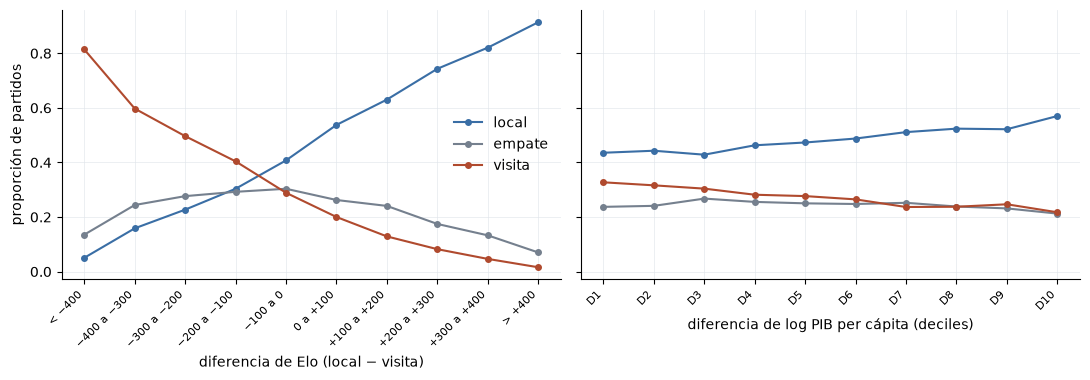


LOS EXTREMOS DE CADA GRÁFICA (train)
--------------------------------------------------------------------
                               local  empate  visita
  Elo < −400                    5.1%   13.5%   81.4%
  Elo entre −100 y +100        47.3%   28.3%   24.4%
  Elo > +400                   91.4%    7.0%    1.6%
  PIB decil 1                  43.6%   23.7%   32.7%
  PIB decil 10                 57.0%   21.3%   21.7%

¿EL DINERO YA ESTÁ DENTRO DEL ELO? (correlaciones en train)
--------------------------------------------------------------------
  dif_elo vs dif_log_pib    0.120
  dif_elo vs dif_log_pob    0.479
  dif_log_pib vs dif_log_pob -0.275


In [6]:
# la relacion que importa: como cambia el resultado con la diferencia de fuerza y de economia
cortes_elo = [-np.inf, -400, -300, -200, -100, 0, 100, 200, 300, 400, np.inf]
etiquetas_elo = ["< −400", "−400 a −300", "−300 a −200", "−200 a −100", "−100 a 0",
                 "0 a +100", "+100 a +200", "+200 a +300", "+300 a +400", "> +400"]
tramos = [
    (pd.cut(tr["dif_elo"], cortes_elo, labels=etiquetas_elo),
     etiquetas_elo, "diferencia de Elo (local − visita)"),
    (pd.qcut(tr["dif_log_pib"], 10, labels=[f"D{i}" for i in range(1, 11)]),
     [f"D{i}" for i in range(1, 11)], "diferencia de log PIB per cápita (deciles)"),
]

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
proporciones = []
for ax, (tramo, etiquetas, nombre) in zip(ejes, tramos):
    prop = pd.crosstab(tramo, tr["resultado"], normalize="index")[["local", "empate", "visita"]]
    proporciones.append(prop)
    for clase, color in [("local", AZUL), ("empate", GRIS), ("visita", ROJO)]:
        ax.plot(range(len(prop)), prop[clase], marker="o", ms=4, color=color, label=clase)
    ax.set_xticks(range(len(etiquetas)))
    ax.set_xticklabels(etiquetas, rotation=45, ha="right", fontsize=8)
    ax.set_xlabel(nombre)
    eje_limpio(ax)
ejes[0].set_ylabel("proporción de partidos")
ejes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

prop_elo, prop_pib = proporciones
titulo("LOS EXTREMOS DE CADA GRÁFICA (train)")
print(f"  {'':<26} {'local':>7} {'empate':>7} {'visita':>7}")
for nombre, fila in [("Elo < −400", prop_elo.iloc[0]), ("Elo entre −100 y +100", None),
                     ("Elo > +400", prop_elo.iloc[-1]),
                     ("PIB decil 1", prop_pib.iloc[0]), ("PIB decil 10", prop_pib.iloc[-1])]:
    if fila is None:
        cerca = tr[tr["dif_elo"].abs() < 100]["resultado"].value_counts(normalize=True)
        fila = cerca.reindex(["local", "empate", "visita"])
    print(f"  {nombre:<26} {fila['local']:>7.1%} {fila['empate']:>7.1%} {fila['visita']:>7.1%}")

titulo("¿EL DINERO YA ESTÁ DENTRO DEL ELO? (correlaciones en train)")
c = tr[["dif_elo", "dif_log_pib", "dif_log_pob"]].corr()
print(f"  dif_elo vs dif_log_pib   {c.loc['dif_elo', 'dif_log_pib']:>6.3f}")
print(f"  dif_elo vs dif_log_pob   {c.loc['dif_elo', 'dif_log_pob']:>6.3f}")
print(f"  dif_log_pib vs dif_log_pob {c.loc['dif_log_pib', 'dif_log_pob']:>4.3f}")

**Lo que importa de este dataset para modelar:** 

1. El local gana el 48.6% de los partidos, así que el modelo tonto saca casi 50% de aciertos sin saber nada de fútbol. El reparto casi no cambia en el test (47.4% local, 23.9% empate, 28.7% visita), así que cortar por fecha no deja un examen raro. Por eso la métrica es F1 macro y no accuracy, que obliga a acertar las tres clases y no solo la más común.

2. El Elo es la señal más fuerte: con más de 400 puntos a favor el local gana el 91.4%, y con más de 400 en contra la visita gana el 81.4%. El empate nunca pasa del 30%, y su punto más alto está en −100, donde la ventaja de jugar en casa empareja a los dos equipos. Ahí las tres clases quedan casi iguales, así que el modelo casi nunca va a elegir empate, y neutral tiene que entrar porque cambia dónde está el partido parejo.

3. La economía mueve poco el resultado: del decil 1 al 10 de PIB, la victoria local solo sube de 43.6% a 57.0%. Además, la población correlaciona 0.479 con la diferencia de Elo, así que buena parte de lo que aportaba en el P1 ya viene dentro del rating. Lo esperable es que el PIB y la población agreguen poco sobre el Elo, pero eso se mide en la validación cruzada, no se supone.

## 3. Separar y preparar

Los partidos tienen fecha, así que **no se barajan**: se corta por fecha. Todo lo jugado antes de 2022 es train y todo desde 2022 es test. Barajar dejaría que el modelo aprenda con partidos de 2024 para predecir uno de 2019, algo que nunca podría pasar al usar el modelo de verdad.

La validación cruzada dentro del train sigue la misma regla con `TimeSeriesSplit`: en cada vuelta se entrena con el pasado y se valida con el bloque de años que viene justo después.

In [7]:
from sklearn.model_selection import TimeSeriesSplit

TARGET = "resultado"
NUMERICAS = ["elo_local", "elo_visita", "dif_elo", "dif_log_pib", "dif_log_pob"]
CATEGORICAS = ["tipo_torneo"]
BINARIAS = ["neutral"]
ECONOMICAS = ["dif_log_pib", "dif_log_pob"]   # las que se quitan para medir si el dinero agrega algo

# df ya viene ordenado por fecha (seccion 1), y el orden se conserva al cortar
train = df[df["date"] < CORTE_TEST]
test = df[df["date"] >= CORTE_TEST]

X_tr, y_tr = train[NUMERICAS + CATEGORICAS + BINARIAS], train[TARGET]
X_te, y_te = test[NUMERICAS + CATEGORICAS + BINARIAS], test[TARGET]

cv = TimeSeriesSplit(n_splits=5)

titulo("CORTE POR FECHA")
print(f"  {'train':<6} {len(train):>7,} partidos   {train['date'].min().date()} a {train['date'].max().date()}")
print(f"  {'test':<6} {len(test):>7,} partidos   {test['date'].min().date()} a {test['date'].max().date()}")

titulo("VALIDACIÓN CRUZADA TEMPORAL DENTRO DEL TRAIN")
print(f"  {'vuelta':<8} {'entrena con':<16} {'valida con':<16} {'n valida':>9}")
for vuelta, (i_ent, i_val) in enumerate(cv.split(X_tr), start=1):
    a = train["year"].iloc[i_ent]
    b = train["year"].iloc[i_val]
    print(f"  {vuelta:<8} {f'{a.min()}–{a.max()}':<16} {f'{b.min()}–{b.max()}':<16} {len(i_val):>9,}")

# Verificacion: ningun partido de test es anterior al ultimo de train
assert train["date"].max() < test["date"].min()


CORTE POR FECHA
--------------------------------------------------------------------
  train   33,121 partidos   1960-01-06 a 2021-12-31
  test     3,557 partidos   2022-01-01 a 2025-12-31

VALIDACIÓN CRUZADA TEMPORAL DENTRO DEL TRAIN
--------------------------------------------------------------------
  vuelta   entrena con      valida con        n valida
  1        1960–1982        1982–1994            5,520
  2        1960–1994        1994–2001            5,520
  3        1960–2001        2001–2008            5,520
  4        1960–2008        2008–2015            5,520
  5        1960–2015        2015–2021            5,520


In [8]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


def armar_preparacion(numericas):
    return ColumnTransformer([
        ("num", Pipeline([("rellenar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
        ("bin", "passthrough", BINARIAS),
    ])


preparacion = armar_preparacion(NUMERICAS)
# la misma receta sin las columnas economicas, para la comparacion de la seccion 5
preparacion_sin_eco = armar_preparacion([c for c in NUMERICAS if c not in ECONOMICAS])

# solo para mostrar que sale: se ajusta una COPIA con el train. La preparacion de verdad se
# ajusta dentro de cada Pipeline, en cada vuelta de la validacion, nunca sobre el test.
muestra = clone(preparacion).fit(X_tr)
nombres = muestra.get_feature_names_out()

titulo("LO QUE LE LLEGA AL MODELO")
print(f"  {len(nombres)} columnas a partir de {X_tr.shape[1]}:")
for nombre in nombres:
    print(f"    {nombre}")


LO QUE LE LLEGA AL MODELO
--------------------------------------------------------------------
  11 columnas a partir de 7:
    num__elo_local
    num__elo_visita
    num__dif_elo
    num__dif_log_pib
    num__dif_log_pob
    cat__tipo_torneo_amistoso
    cat__tipo_torneo_continental
    cat__tipo_torneo_eliminatoria
    cat__tipo_torneo_mundial
    cat__tipo_torneo_otro
    bin__neutral


**Por qué se preparó así:**

- **Rellenos con la mediana.** Hoy no hay ningún hueco en las columnas del modelo, pero el relleno queda dentro del `Pipeline` para que un partido nuevo con un dato faltante no rompa el modelo. Si llegara a usarse, la mediana se calcula solo con el train de cada vuelta.

- **Numéricas escaladas.** La regresión logística compara coeficientes y penaliza su tamaño, así que necesita las columnas en la misma escala: el Elo se mide en cientos de puntos y las diferencias de log en unidades. Al boosting no le cambia nada, pero se usa la misma receta para que los modelos se comparen en igualdad de condiciones.

- **`tipo_torneo` en one-hot.** Son cinco categorías sin orden entre ellas (un Mundial no es "dos amistosos"), y `handle_unknown="ignore"` evita que el modelo se rompa si aparece un tipo nuevo.

- **Se dejan `elo_local` y `elo_visita` además de `dif_elo`.** La diferencia dice quién es favorito, pero el nivel también importa: un partido entre dos equipos de 2000 puntos no se juega igual que uno entre dos de 1400, aunque la diferencia sea la misma.

- **Hay una segunda receta sin `dif_log_pib` ni `dif_log_pob`.** Es la que permite responder la segunda pregunta del proyecto en la sección 5: el mismo modelo con y sin economía, medido en la misma validación.

## 4. Modelos de comparación

Dos puntos de comparación antes del ensamble: el **modelo tonto**, que siempre dice "gana el local", y un **modelo simple**, la regresión logística. Los dos se miden con la misma validación cruzada temporal de la sección 3 y con las mismas tres métricas. Solo se usa el train.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, log_loss, accuracy_score

CLASES = ["local", "empate", "visita"]


# validacion cruzada temporal hecha a mano: en cada vuelta se clona el Pipeline completo
# (preparacion + modelo), se ajusta con el pasado y se mide en el bloque siguiente.
# Se hace a mano para poder contar tambien cuantos empates predice el modelo.
def validar(nombre, modelo, X=X_tr, y=y_tr):
    f1s, perdidas, aciertos, empates = [], [], [], []
    for i_ent, i_val in cv.split(X):
        m = clone(modelo).fit(X.iloc[i_ent], y.iloc[i_ent])
        pred = m.predict(X.iloc[i_val])
        proba = m.predict_proba(X.iloc[i_val])
        f1s.append(f1_score(y.iloc[i_val], pred, average="macro"))
        perdidas.append(log_loss(y.iloc[i_val], proba, labels=m.classes_))
        aciertos.append(accuracy_score(y.iloc[i_val], pred))
        empates.append((pred == "empate").mean())
    return {"modelo": nombre,
            "f1_macro": np.mean(f1s), "f1_std": np.std(f1s),
            "log_loss": np.mean(perdidas), "accuracy": np.mean(aciertos),
            "pred_empate": np.mean(empates), "f1_vueltas": f1s}


def mostrar_cv(filas):
    titulo("VALIDACIÓN CRUZADA TEMPORAL (5 vueltas, solo train)")
    print(f"  {'modelo':<30} {'F1 macro':>12} {'log-loss':>9} {'accuracy':>9} {'predice empate':>15}")
    for f in filas:
        print(f"  {f['modelo']:<30} {f['f1_macro']:>6.4f} ±{f['f1_std']:.3f} {f['log_loss']:>9.4f} "
              f"{f['accuracy']:>9.1%} {f['pred_empate']:>15.1%}")


# modelo tonto: siempre la clase mas comun del train ("gana el local").
# strategy="prior" predice lo mismo que "most_frequent", pero sus probabilidades son el
# reparto de clases del train en vez de un 100% al local, asi el log-loss tiene sentido.
tonto = Pipeline([("prep", preparacion), ("modelo", DummyClassifier(strategy="prior"))])

resultados_cv = [validar("Tonto (siempre local)", tonto)]
mostrar_cv(resultados_cv)


VALIDACIÓN CRUZADA TEMPORAL (5 vueltas, solo train)
--------------------------------------------------------------------
  modelo                             F1 macro  log-loss  accuracy  predice empate
  Tonto (siempre local)          0.2167 ±0.003    1.0523     48.2%            0.0%


In [10]:
# modelo simple: regresion logistica multinomial, en dos versiones.
# la segunda le da a cada clase un peso inverso a su frecuencia, para que equivocarse en un
# empate (24% de los partidos) cueste tanto como equivocarse en una victoria local (49%).
logistica = Pipeline([("prep", preparacion),
                      ("modelo", LogisticRegression(max_iter=2000))])
logistica_bal = Pipeline([("prep", preparacion),
                          ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))])

resultados_cv += [validar("Logística", logistica),
                  validar("Logística balanceada", logistica_bal)]
mostrar_cv(resultados_cv)

titulo("F1 MACRO EN CADA VUELTA")
print(f"  {'modelo':<30}" + "".join(f"{f'v{k}':>8}" for k in range(1, 6)))
for f in resultados_cv:
    print(f"  {f['modelo']:<30}" + "".join(f"{v:>8.3f}" for v in f["f1_vueltas"]))


VALIDACIÓN CRUZADA TEMPORAL (5 vueltas, solo train)
--------------------------------------------------------------------
  modelo                             F1 macro  log-loss  accuracy  predice empate
  Tonto (siempre local)          0.2167 ±0.003    1.0523     48.2%            0.0%
  Logística                      0.4235 ±0.012    0.9095     57.2%            1.0%
  Logística balanceada           0.5025 ±0.014    0.9412     54.4%           22.1%

F1 MACRO EN CADA VUELTA
--------------------------------------------------------------------
  modelo                              v1      v2      v3      v4      v5
  Tonto (siempre local)            0.213   0.222   0.216   0.217   0.215
  Logística                        0.403   0.424   0.423   0.427   0.440
  Logística balanceada             0.483   0.504   0.507   0.493   0.526


**Métrica elegida y por qué:**

- **Principal: F1 macro.** Calcula el F1 de cada una de las tres clases por separado y las promedia con el mismo peso. El error que más cuesta en este problema es **ignorar una clase entera**, un modelo que nunca dice "empate" o "gana la visita" puede tener un accuracy decente solo porque el local gana casi la mitad de las veces, y aun así no sirve para lo que se le pregunta. El F1 macro nos permite ver mas allá de eso, porque un empate que nunca se predice deja su clase en cero y hunde el promedio.

- **Secundaria: log-loss.** Mide qué tan buenas son las probabilidadesa. Es la métrica que importa si la pregunta es "¿qué chance tiene Guatemala de no perder?", porque castiga mucho al modelo que dice 90% y se equivoca. Más bajo es mejor.

- **El accuracy se reporta solo como referencia**, para que se vea por qué no sirve: el tonto saca casi el 50% sin saber nada de fútbol.

- **Por qué se prueban dos logísticas.** La normal busca acertar el mayor número de partidos y por eso casi nunca elige empate. La balanceada le da a cada clase un peso inverso a su frecuencia, por lo que equivocarse en un empate cuesta tanto como en una victoria local. Es la forma de decirle al modelo cuál error nos importa y la validación decide cuál de las dos sirve más para el F1 macro.

## 5. Ensamble y búsqueda de opciones

El ensamble es **gradient boosting** (`HistGradientBoostingClassifier`): árboles en fila donde cada uno corrige lo que al anterior le faltó. Se eligió boosting y no bosque porque la sección 2 mostró una relación suave y monótona con el Elo, que el boosting aproxima bien con árboles chicos, y porque con 33 mil filas entrena en segundos.

El `Pipeline` completo (preparación + modelo) va **dentro** del buscador, así que en cada vuelta de la validación temporal se vuelve a calcular la escala con el pasado de esa vuelta. La búsqueda elige con **F1 macro** en validación; el test no se toca.

In [11]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

pipe = Pipeline([("prep", preparacion),
                 ("modelo", HistGradientBoostingClassifier(early_stopping=False,
                                                           random_state=RANDOM_STATE))])

opciones = {
    "modelo__learning_rate":    [0.02, 0.05, 0.1, 0.2],
    "modelo__max_iter":         [100, 200, 400],
    "modelo__max_leaf_nodes":   [7, 15, 31],
    "modelo__min_samples_leaf": [20, 50, 100, 200],
    "modelo__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "modelo__class_weight":     [None, "balanced"],
}
n_combinaciones = int(np.prod([len(v) for v in opciones.values()]))

busqueda = RandomizedSearchCV(pipe, opciones, n_iter=40, scoring="f1_macro", cv=cv,
                              random_state=RANDOM_STATE, n_jobs=-1)

inicio = time.time()
busqueda.fit(X_tr, y_tr)

titulo("BÚSQUEDA ALEATORIA")
print(f"  {n_combinaciones:,} combinaciones posibles, se probaron 40 al azar x 5 vueltas "
      f"= 200 ajustes  ({time.time() - inicio:.0f} s)")

tabla = pd.DataFrame(busqueda.cv_results_).sort_values("rank_test_score")
titulo("LAS 8 MEJORES COMBINACIONES (F1 macro en validación)")
print(f"  {'rank':<5} {'F1 macro':>14} {'lr':>6} {'árboles':>8} {'hojas':>6} "
      f"{'min hoja':>9} {'l2':>6} {'pesos':>10}")
for _, f in tabla.head(8).iterrows():
    print(f"  {f['rank_test_score']:<5} {f['mean_test_score']:>7.4f} ±{f['std_test_score']:.3f} "
          f"{f['param_modelo__learning_rate']:>6} {f['param_modelo__max_iter']:>8} "
          f"{f['param_modelo__max_leaf_nodes']:>6} {f['param_modelo__min_samples_leaf']:>9} "
          f"{f['param_modelo__l2_regularization']:>6} {str(f['param_modelo__class_weight']):>10}")

titulo("¿QUÉ PESA MÁS EN LA BÚSQUEDA? (F1 promedio de las combinaciones probadas)")
for param in ["modelo__class_weight", "modelo__learning_rate", "modelo__max_leaf_nodes"]:
    # map(str) y no astype(str): en pandas 3 astype deja el None como faltante y groupby lo descarta
    medias = tabla.groupby(tabla[f"param_{param}"].map(str))["mean_test_score"].mean()
    print(f"  {param.replace('modelo__', ''):<16} "
          + "   ".join(f"{k}: {v:.3f}" for k, v in medias.items()))


BÚSQUEDA ALEATORIA
--------------------------------------------------------------------
  1,152 combinaciones posibles, se probaron 40 al azar x 5 vueltas = 200 ajustes  (32 s)

LAS 8 MEJORES COMBINACIONES (F1 macro en validación)
--------------------------------------------------------------------
  rank        F1 macro     lr  árboles  hojas  min hoja     l2      pesos
  1      0.5058 ±0.017   0.02      100     15       200    0.1   balanced
  2      0.5033 ±0.017   0.05      100      7        50    0.0   balanced
  3      0.5023 ±0.017   0.02      100     31        20    0.0   balanced
  4      0.4995 ±0.018    0.1      100      7       100    0.0   balanced
  5      0.4992 ±0.019    0.1      100      7       200    1.0   balanced
  6      0.4975 ±0.018    0.1      200      7       200    0.1   balanced
  7      0.4969 ±0.018   0.02      200     31        20    0.1   balanced
  8      0.4968 ±0.018   0.05      200     15        50    0.0   balanced

¿QUÉ PESA MÁS EN LA BÚSQUEDA? (F

In [12]:
# el ganador de la busqueda, medido con la misma funcion de la seccion 4 para que las cifras
# sean comparables (incluye log-loss y cuantos empates predice)
boosting = clone(busqueda.best_estimator_)
resultados_cv.append(validar("Boosting (mejor búsqueda)", boosting))
mostrar_cv(resultados_cv)

titulo("MEJOR COMBINACIÓN")
for k, v in busqueda.best_params_.items():
    print(f"  {k.replace('modelo__', ''):<20} {v}")


VALIDACIÓN CRUZADA TEMPORAL (5 vueltas, solo train)
--------------------------------------------------------------------
  modelo                             F1 macro  log-loss  accuracy  predice empate
  Tonto (siempre local)          0.2167 ±0.003    1.0523     48.2%            0.0%
  Logística                      0.4235 ±0.012    0.9095     57.2%            1.0%
  Logística balanceada           0.5025 ±0.014    0.9412     54.4%           22.1%
  Boosting (mejor búsqueda)      0.5058 ±0.017    0.9426     54.0%           24.7%

MEJOR COMBINACIÓN
--------------------------------------------------------------------
  min_samples_leaf     200
  max_leaf_nodes       15
  max_iter             100
  learning_rate        0.02
  l2_regularization    0.1
  class_weight         balanced


In [13]:
# ¿agrega algo el dinero? el mismo modelo con y sin dif_log_pib y dif_log_pob, en la misma
# validacion. Para el boosting se usan los hiperparametros ganadores, sin volver a buscar.
def sin_economia(modelo):
    return clone(modelo).set_params(prep=preparacion_sin_eco)

comparacion = []
for nombre, modelo in [("Logística balanceada", logistica_bal), ("Boosting", boosting)]:
    con = validar(nombre, modelo)
    sin = validar(nombre, sin_economia(modelo))
    dif = np.array(con["f1_vueltas"]) - np.array(sin["f1_vueltas"])
    comparacion.append({"modelo": nombre, "con": con["f1_macro"], "sin": sin["f1_macro"],
                        "dif": dif.mean(), "dif_std": dif.std(), "dif_vueltas": dif,
                        "ll_con": con["log_loss"], "ll_sin": sin["log_loss"]})

titulo("¿AGREGA ALGO EL DINERO? (F1 macro en validación)")
print(f"  {'modelo':<22} {'con economía':>13} {'sin economía':>13} {'diferencia':>18}")
for c in comparacion:
    print(f"  {c['modelo']:<22} {c['con']:>13.4f} {c['sin']:>13.4f} "
          f"{c['dif']:>+10.4f} ±{c['dif_std']:.4f}")
print()
for c in comparacion:
    print(f"  {c['modelo']:<22} diferencia por vuelta: "
          + "  ".join(f"{d:+.3f}" for d in c["dif_vueltas"]))
    print(f"  {'':<22} log-loss con / sin:    {c['ll_con']:.4f} / {c['ll_sin']:.4f}")


¿AGREGA ALGO EL DINERO? (F1 macro en validación)
--------------------------------------------------------------------
  modelo                  con economía  sin economía         diferencia
  Logística balanceada          0.5025        0.5017    +0.0008 ±0.0041
  Boosting                      0.5058        0.5043    +0.0015 ±0.0038

  Logística balanceada   diferencia por vuelta: -0.003  +0.006  +0.005  -0.003  -0.001
                         log-loss con / sin:    0.9412 / 0.9453
  Boosting               diferencia por vuelta: +0.001  -0.001  +0.008  -0.003  +0.002
                         log-loss con / sin:    0.9426 / 0.9471


In [14]:
# la regla para elegir el modelo final se fijo ANTES de tocar el test:
#  1) gana la familia con mayor F1 macro en validacion (logistica vs boosting)
#  2) la economia se queda solo si mejora el F1 por mas de una desviacion estandar
#     de la diferencia entre vueltas; si no, el modelo final va sin ella
por_familia = {"Logística balanceada": (logistica_bal, resultados_cv[2]["f1_macro"]),
               "Boosting": (boosting, resultados_cv[3]["f1_macro"])}
familia = max(por_familia, key=lambda k: por_familia[k][1])
c = next(x for x in comparacion if x["modelo"] == familia)
economia_se_queda = c["dif"] > c["dif_std"]

modelo_final = por_familia[familia][0] if economia_se_queda else sin_economia(por_familia[familia][0])
nombre_final = f"{familia} {'con' if economia_se_queda else 'sin'} economía"

titulo("MODELO FINAL (decidido solo con validación)")
print(f"  familia ganadora     {familia}  (F1 macro {por_familia[familia][1]:.4f})")
print(f"  ¿la economía ayuda?  {c['dif']:+.4f} contra una variación de ±{c['dif_std']:.4f}  ->  "
      f"{'sí, se queda' if economia_se_queda else 'no alcanza, se quita'}")
print(f"  modelo final         {nombre_final}")


MODELO FINAL (decidido solo con validación)
--------------------------------------------------------------------
  familia ganadora     Boosting  (F1 macro 0.5058)
  ¿la economía ayuda?  +0.0015 contra una variación de ±0.0038  ->  no alcanza, se quita
  modelo final         Boosting sin economía


**Qué se probó y por qué ese rango:**

| Opción | Valores | Por qué ese rango |
|---|---|---|
| `learning_rate` | 0.02, 0.05, 0.1, 0.2 | Qué fracción de su corrección agrega cada árbol (el "paso" de la HDT 6). Con pasos chicos aprende despacio pero estable; con 0.2 corrige rápido y se puede pasar. El 0.1 es el valor por defecto y queda en medio |
| `max_iter` | 100, 200, 400 | Cuántos árboles en fila. Va de la mano del paso: un paso chico necesita más árboles para llegar al mismo lugar |
| `max_leaf_nodes` | 7, 15, 31 | Qué tan complejo es cada árbol. La sección 2 mostró una relación suave con el Elo, así que no hacen falta árboles grandes; 31 es el valor por defecto y se probó como techo |
| `min_samples_leaf` | 20, 50, 100, 200 | Cuántos partidos como mínimo en cada hoja. El fútbol tiene mucho azar, y hojas grandes evitan que el modelo memorice resultados raros |
| `l2_regularization` | 0, 0.1, 1, 10 | Castiga las correcciones grandes de cada hoja. Escala logarítmica porque su efecto se nota por órdenes de magnitud |
| `class_weight` | ninguno, balanceado | La sección 4 mostró que sin pesos el modelo casi no predice empates. Se deja que la validación decida si al boosting le pasa lo mismo |

Son 1,152 combinaciones posibles, y probarlas todas serían 5,760 ajustes. Se usó **búsqueda aleatoria con 40 combinaciones**: con seis opciones, unas pocas importan mucho y el resto casi nada, y 40 muestras al azar cubren bien los valores de las que importan sin gastar el tiempo de probarlas todas.

**Mejor combinación y su puntaje en validación:**
La mejor combinación usa un paso pequeño (0.02), 100 árboles de 15 hojas como máximo, al menos 200 partidos por hoja, un poco de regularización (0.1) y pesos balanceados. Saca 0.506 de F1 macro en validación, contra 0.503 de la logística balanceada y 0.217 del tonto. Lo que sí pesó fue class_weight: las 8 mejores combinaciones son balanceadas, igual que pasó con la logística, porque sin pesos el modelo casi no predice empates.

**¿Agrega algo el dinero?**
No. Con el PIB y la población, el F1 macro del boosting sube apenas de 0.504 a 0.506 (+0.0015), y la diferencia cambia de signo según la vuelta, de −0.003 a +0.008. Con la logística pasa lo mismo (+0.0008). Como la mejora es menor que la variación entre vueltas (±0.0038), el modelo final va sin economía. Las probabilidades mejoran un poquito con ella (log-loss de 0.947 a 0.943), pero no lo suficiente para cambiar qué resultado se predice. 

## 6. Evaluación final

Aquí, y solo aquí, se toca el test: los 3,557 partidos jugados desde 2022. Los tres modelos se reentrenan con **todo** el train (1960–2021) y se evalúan **una sola vez**. El modelo final ya quedó decidido en la sección 5 con la regla fijada de antemano; después de esta celda no se ajusta nada.

In [15]:
# las cifras de validacion del modelo final salen de la comparacion con y sin economia (seccion 5)
cv_final_f1 = c["con"] if economia_se_queda else c["sin"]
cv_final_ll = c["ll_con"] if economia_se_queda else c["ll_sin"]

candidatos = [
    ("Tonto (siempre local)", tonto, resultados_cv[0]["f1_macro"], resultados_cv[0]["log_loss"]),
    ("Logística balanceada", logistica_bal, resultados_cv[2]["f1_macro"], resultados_cv[2]["log_loss"]),
    (nombre_final, modelo_final, cv_final_f1, cv_final_ll),
]

filas = []
for nombre, modelo, f1_cv, ll_cv in candidatos:
    ajustado = clone(modelo).fit(X_tr, y_tr)
    pred = ajustado.predict(X_te)
    proba = ajustado.predict_proba(X_te)
    filas.append({"modelo": nombre, "f1_cv": f1_cv, "f1_test": f1_score(y_te, pred, average="macro"),
                  "ll_cv": ll_cv, "ll_test": log_loss(y_te, proba, labels=ajustado.classes_),
                  "acc_test": accuracy_score(y_te, pred), "empate_test": (pred == "empate").mean()})
    if modelo is modelo_final:
        final_ajustado, pred_te, proba_te = ajustado, pred, proba

titulo("EL TEST, UNA SOLA VEZ (3,557 partidos de 2022 a 2025)")
print(f"  {'modelo':<26} {'F1 macro':>17} {'log-loss':>17} {'accuracy':>9} {'predice':>8}")
print(f"  {'':<26} {'valid.':>8} {'test':>8} {'valid.':>8} {'test':>8} {'test':>9} {'empate':>8}")
for f in filas:
    print(f"  {f['modelo']:<26} {f['f1_cv']:>8.4f} {f['f1_test']:>8.4f} {f['ll_cv']:>8.4f} "
          f"{f['ll_test']:>8.4f} {f['acc_test']:>9.1%} {f['empate_test']:>8.1%}")


EL TEST, UNA SOLA VEZ (3,557 partidos de 2022 a 2025)
--------------------------------------------------------------------
  modelo                              F1 macro          log-loss  accuracy  predice
                               valid.     test   valid.     test      test   empate
  Tonto (siempre local)        0.2167   0.2144   1.0523   1.0548     47.4%     0.0%
  Logística balanceada         0.5025   0.4958   0.9412   0.9195     55.3%    18.1%
  Boosting sin economía        0.5043   0.5126   0.9471   0.9184     55.8%    21.5%



F1 DE CADA CLASE EN TEST
--------------------------------------------------------------------
              precision    recall  f1-score   support

       local      0.698     0.667     0.682      1686
      empate      0.292     0.263     0.277       849
      visita      0.540     0.624     0.579      1022

    accuracy                          0.558      3557
   macro avg      0.510     0.518     0.513      3557
weighted avg      0.556     0.558     0.556      3557



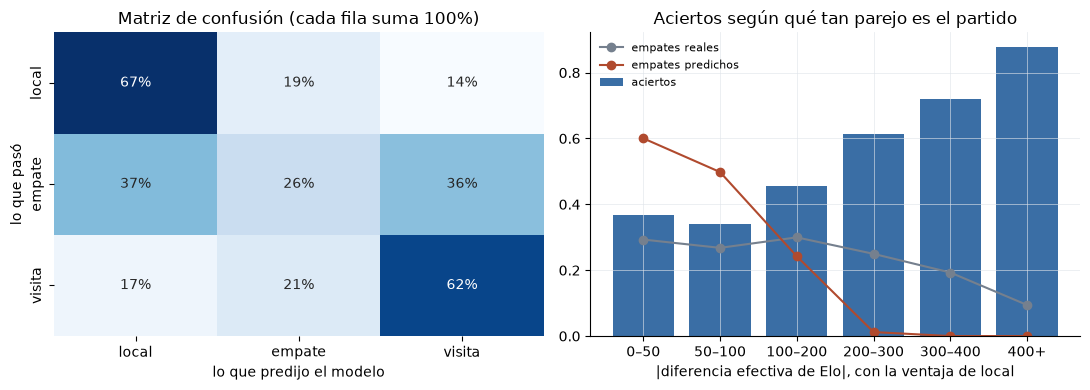


ACIERTOS SEGÚN QUÉ TAN PAREJO ES EL PARTIDO (test)
--------------------------------------------------------------------
  |dif. efectiva|   partidos   acierto  empates reales  empates pred.
  0–50                   488     36.9%           29.3%          60.0%
  50–100                 504     34.1%           26.8%          49.8%
  100–200                871     45.7%           30.0%          24.2%
  200–300                661     61.3%           25.0%           1.2%
  300–400                482     72.0%           19.3%           0.0%
  400+                   551     87.8%            9.4%           0.0%

ACIERTOS POR TIPO DE TORNEO (test)
--------------------------------------------------------------------
  amistoso          953 partidos   acierto  52.8%   F1 macro 0.490
  continental       328 partidos   acierto  52.7%   F1 macro 0.505
  eliminatoria    1,899 partidos   acierto  58.3%   F1 macro 0.519
  mundial            64 partidos   acierto  48.4%   F1 macro 0.467
  otro          

In [16]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

titulo("F1 DE CADA CLASE EN TEST")
print(classification_report(y_te, pred_te, labels=CLASES, digits=3))

# la "diferencia efectiva" suma la ventaja de local, que es como el Elo ve el partido:
# cerca de cero, los dos equipos llegan parejos
evaluacion = test.assign(pred=pred_te, acierto=pred_te == y_te.to_numpy())
evaluacion["dif_efectiva"] = evaluacion["dif_elo"] + np.where(evaluacion["neutral"], 0, VENTAJA_LOCAL)
tramo = pd.cut(evaluacion["dif_efectiva"].abs(), [0, 50, 100, 200, 300, 400, np.inf], right=False,
               labels=["0–50", "50–100", "100–200", "200–300", "300–400", "400+"])
por_tramo = evaluacion.groupby(tramo, observed=True).agg(
    partidos=("acierto", "size"), acierto=("acierto", "mean"),
    empates_reales=("resultado", lambda s: (s == "empate").mean()),
    empates_predichos=("pred", lambda s: (s == "empate").mean()))

matriz = confusion_matrix(y_te, pred_te, labels=CLASES, normalize="true")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(matriz, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ejes[0],
            xticklabels=CLASES, yticklabels=CLASES)
ejes[0].set_xlabel("lo que predijo el modelo")
ejes[0].set_ylabel("lo que pasó")
ejes[0].set_title("Matriz de confusión (cada fila suma 100%)")

x = np.arange(len(por_tramo))
ejes[1].bar(x, por_tramo["acierto"], color=AZUL, label="aciertos")
ejes[1].plot(x, por_tramo["empates_reales"], color=GRIS, marker="o", label="empates reales")
ejes[1].plot(x, por_tramo["empates_predichos"], color=ROJO, marker="o", label="empates predichos")
ejes[1].set_xticks(x)
ejes[1].set_xticklabels(por_tramo.index)
ejes[1].set_xlabel("|diferencia efectiva de Elo|, con la ventaja de local")
ejes[1].set_title("Aciertos según qué tan parejo es el partido")
ejes[1].legend(frameon=False, fontsize=8)
eje_limpio(ejes[1])
plt.tight_layout()
plt.show()

titulo("ACIERTOS SEGÚN QUÉ TAN PAREJO ES EL PARTIDO (test)")
print(f"  {'|dif. efectiva|':<16} {'partidos':>9} {'acierto':>9} {'empates reales':>15} {'empates pred.':>14}")
for t, f in por_tramo.iterrows():
    print(f"  {t:<16} {f['partidos']:>9,.0f} {f['acierto']:>9.1%} {f['empates_reales']:>15.1%} "
          f"{f['empates_predichos']:>14.1%}")

titulo("ACIERTOS POR TIPO DE TORNEO (test)")
for tipo, g in evaluacion.groupby("tipo_torneo"):
    print(f"  {tipo:<14} {len(g):>6,} partidos   acierto {g['acierto'].mean():>6.1%}   "
          f"F1 macro {f1_score(g['resultado'], g['pred'], average='macro'):.3f}")

**Comparación contra los modelos de comparación:**

| Modelo | F1 macro (validación) | F1 macro (test) | log-loss (validación) | log-loss (test) | Accuracy (test) |
|---|---|---|---|---|---|
| Tonto (siempre local) | 0.217 | 0.214 | 1.052 | 1.055 | 47.4% |
| Simple: logística balanceada | 0.503 | 0.496 | 0.941 | 0.920 | 55.3% |
| **Ensamble: boosting sin economía** | **0.504** | **0.513** | 0.947 | **0.918** | **55.8%** |

El test confirma lo que dijo la validación: el boosting y la logística quedan prácticamente empatados, muy por encima del tonto, y las cifras de test no se alejan de las de validación (el modelo no estaba sobreajustado a 1960–2021).

**Dónde falla el modelo:**

- Los empates es lo que más le cuesta. El F1 es 0.682 para local, 0.579 para visita y apenas 0.277 para empate. En la matriz de confusión, de los empates reales solo detecta el 26%, el 37% los confunde con victoria local y el 36% con victoria visitante.

- Falla en los partidos parejos y acierta en los desiguales. Con menos de 100 puntos de diferencia efectiva (contando la ventaja de local) acierta solo dell 34 al 37%, casi como lanzar un dado de tres caras. Con más de 400 puntos acierta el 87.8%.

- Cuando el partido es muy parejo (0–50) predice empate en el 60% de los partidos, pero en la realidad solo hay 29%. Con más de 200 puntos de diferencia ya nunca predice empate, aunque todavía ocurren entre 9% y 25%.

- Por torneo casi no cambia. Le va mejor en las eliminatorias (58.3% de aciertos) y peor en los Mundiales (48.4%, con solo 64 partidos), donde se enfrentan equipos parejos.

## 7. Análisis sin respuestas

**Ruta A, agrupar.** Se agrupan los **partidos** según su perfil antes de jugarse, sin mirar el resultado, con k-Means sobre tres columnas escaladas:

| Columna | Qué mide |
|---|---|
| `nivel` | Elo promedio de los dos equipos: ¿juegan dos potencias o dos selecciones chicas? |
| `desnivel` | Diferencia de Elo en valor absoluto, contando la ventaja de local (la "diferencia efectiva" de la sección 6): ¿es un partido parejo o hay un favorito claro? |
| `brecha_pib` | Diferencia de log PIB per cápita en valor absoluto: ¿se enfrentan países de economías parecidas o uno mucho más rico que el otro? |

Se dejaron fuera `neutral` y el tipo de torneo. Se probaron, pero al ser columnas de 0 y 1, una vez escaladas pesan tanto en la distancia que el k-Means solo separaba "neutral contra no neutral" y "amistoso contra oficial", grupos que ya se conocen sin necesidad de agrupar.

El escalador y el k-Means se ajustan con el **train** y después se usan para asignarle grupo a cada partido del test, que es lo que se cruza con los errores del modelo en la sección 8.

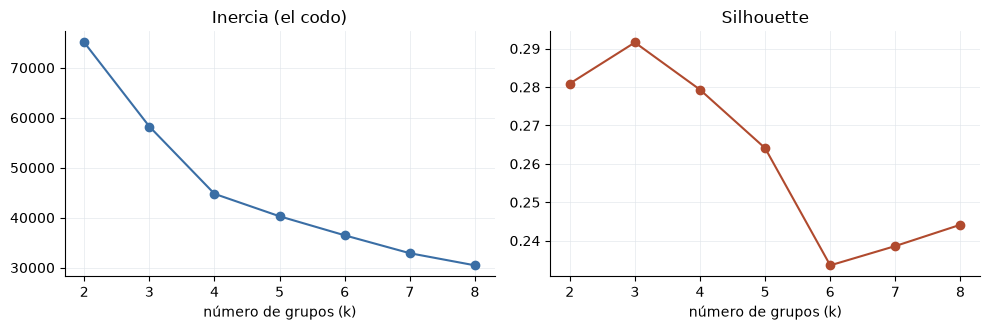


¿CUÁNTOS GRUPOS?
--------------------------------------------------------------------
  k       inercia  silhouette
  2        75,063       0.281
  3        58,242       0.292
  4        44,775       0.279
  5        40,281       0.264
  6        36,473       0.234
  7        32,891       0.239
  8        30,463       0.244


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

COLUMNAS_PERFIL = ["nivel", "desnivel", "brecha_pib"]

def perfil_partido(datos):
    return pd.DataFrame({
        "nivel": (datos["elo_local"] + datos["elo_visita"]) / 2,
        "desnivel": (datos["dif_elo"] + np.where(datos["neutral"], 0, VENTAJA_LOCAL)).abs(),
        "brecha_pib": datos["dif_log_pib"].abs(),
    }, index=datos.index)

def armar_agrupador(k):
    return Pipeline([("escalar", StandardScaler()),
                     ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE))])

perfil_tr = perfil_partido(train)
perfil_te = perfil_partido(test)

inercias, siluetas = {}, {}
for k in range(2, 9):
    agrupador_k = armar_agrupador(k).fit(perfil_tr)
    Z = agrupador_k.named_steps["escalar"].transform(perfil_tr)
    inercias[k] = agrupador_k.named_steps["kmeans"].inertia_
    # el silhouette exacto compara todos contra todos (33 mil x 33 mil): se calcula sobre 6,000 al azar
    siluetas[k] = silhouette_score(Z, agrupador_k.named_steps["kmeans"].labels_,
                                   sample_size=6000, random_state=RANDOM_STATE)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4))
ejes[0].plot(list(inercias), list(inercias.values()), marker="o", color=AZUL)
ejes[0].set_title("Inercia (el codo)")
ejes[1].plot(list(siluetas), list(siluetas.values()), marker="o", color=ROJO)
ejes[1].set_title("Silhouette")
for ax in ejes:
    ax.set_xlabel("número de grupos (k)")
    eje_limpio(ax)
plt.tight_layout()
plt.show()

titulo("¿CUÁNTOS GRUPOS?")
print(f"  {'k':<4} {'inercia':>10} {'silhouette':>11}")
for k in inercias:
    print(f"  {k:<4} {inercias[k]:>10,.0f} {siluetas[k]:>11.3f}")


PERFIL DE LOS 4 GRUPOS (train)
--------------------------------------------------------------------
  grupo   partidos  Elo prom.  desnivel  PIB rico/pobre  empates  gana favorito
  0          6,381       1557       167           12.3x    24.0%          56.8%
  1         10,725       1467       126            1.9x    26.5%          51.5%
  2          5,370       1564       455            2.6x    12.7%          82.6%
  3         10,645       1771       140            2.0x    28.3%          50.2%
  (PIB rico/pobre: mediana de cuántas veces más PIB per cápita tiene el país más rico)

TRES PARTIDOS TÍPICOS DE CADA GRUPO (los más cercanos al centro)
--------------------------------------------------------------------
  grupo 0
    2008    Northern Ireland 4-1 Georgia            Friendly
    2010  Trinidad and Tobago 4-0 Haiti              CFU Caribbean Cup qualification
    1970             Myanmar 1-0 Malaysia           Asian Games
  grupo 1
    1992  Antigua and Barbuda 1-1 Suriname     

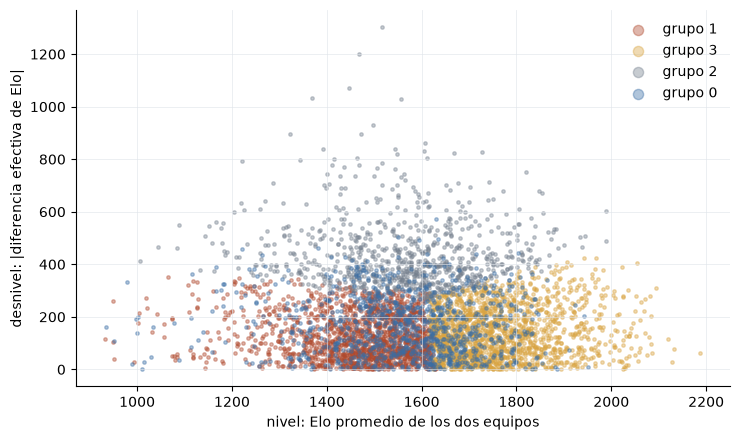

In [18]:
K = 4   # ver la justificacion abajo: el silhouette casi no distingue entre 2, 3 y 4
agrupador = armar_agrupador(K).fit(perfil_tr)
grupo_tr = agrupador.predict(perfil_tr)
grupo_te = agrupador.predict(perfil_te)

descripcion = (perfil_tr
               .assign(grupo=grupo_tr, resultado=train["resultado"],
                       veces_pib=np.exp(perfil_tr["brecha_pib"]))
               .groupby("grupo")
               .agg(partidos=("nivel", "size"), nivel=("nivel", "mean"),
                    desnivel=("desnivel", "mean"), veces_pib=("veces_pib", "median"),
                    empate=("resultado", lambda s: (s == "empate").mean())))

# quien gana: el favorito es el equipo con mas Elo efectivo (contando la ventaja de local)
favorito_local = (train["dif_elo"] + np.where(train["neutral"], 0, VENTAJA_LOCAL)) >= 0
gano_favorito = np.where(favorito_local, train["resultado"] == "local", train["resultado"] == "visita")
descripcion["gana_favorito"] = pd.Series(gano_favorito).groupby(grupo_tr).mean()

titulo(f"PERFIL DE LOS {K} GRUPOS (train)")
print(f"  {'grupo':<6} {'partidos':>9} {'Elo prom.':>10} {'desnivel':>9} {'PIB rico/pobre':>15} "
      f"{'empates':>8} {'gana favorito':>14}")
for g, f in descripcion.iterrows():
    print(f"  {g:<6} {f['partidos']:>9,.0f} {f['nivel']:>10.0f} {f['desnivel']:>9.0f} "
          f"{f['veces_pib']:>14.1f}x {f['empate']:>8.1%} {f['gana_favorito']:>14.1%}")
print("  (PIB rico/pobre: mediana de cuántas veces más PIB per cápita tiene el país más rico)")

# los partidos mas tipicos de cada grupo: los mas cercanos a su centro
distancias = agrupador.transform(perfil_tr)
titulo("TRES PARTIDOS TÍPICOS DE CADA GRUPO (los más cercanos al centro)")
for g in range(K):
    print(f"  grupo {g}")
    en_grupo = np.flatnonzero(grupo_tr == g)
    for i in en_grupo[np.argsort(distancias[en_grupo, g])[:3]]:
        f = train.iloc[i]
        print(f"    {f['date'].year}  {f['home_team']:>18} {f['home_score']}-{f['away_score']} "
              f"{f['away_team']:<18} {f['tournament']}")

# el mapa: nivel contra desnivel, coloreado por grupo (una muestra para que se vea)
muestra = perfil_tr.assign(grupo=grupo_tr).sample(5000, random_state=RANDOM_STATE)
colores = [AZUL, ROJO, GRIS, "#D9A441"]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
# el grupo de la brecha economica se dibuja al final: se separa por el PIB, que no esta en
# los ejes, y si va abajo queda tapado por los demas
for g in sorted(range(K), key=lambda g: descripcion.loc[g, "veces_pib"]):
    s = muestra[muestra["grupo"] == g]
    ax.scatter(s["nivel"], s["desnivel"], s=6, alpha=0.4, color=colores[g], label=f"grupo {g}")
ax.set_xlabel("nivel: Elo promedio de los dos equipos")
ax.set_ylabel("desnivel: |diferencia efectiva de Elo|")
ax.legend(frameon=False, markerscale=3)
eje_limpio(ax)
plt.tight_layout()
plt.show()

**Por qué 4 grupos:** el silhouette casi no cambia entre 2 y 4 grupos (0.281, 0.292 y 0.279), así que no decide por sí solo. Se eligieron 4 porque es el número más chico en el que cada grupo cuenta una historia futbolística distinta. Con 3, los partidos parejos entre potencias y los parejos entre selecciones chicas quedan en un mismo grupo de 18 mil partidos, y esa diferencia de nivel es justo la que importa para los empates (28.3% contra 26.5%). Con 5, el grupo de la brecha económica se parte en dos (países 17 y 7 veces más ricos que su rival) sin que cambie lo que pasa en la cancha.

**Interpretación:**

| Grupo | Nombre en palabras del negocio | Qué lo caracteriza | Tamaño |
|---|---|---|---|
| 0 | La diferencia está en la billetera | Uno de los dos países es 12 veces más rico que el otro, pero en la cancha están casi parejos (167 de desnivel). El dinero de más no se nota: el favorito gana el 56.8%, poco más que en los partidos parejos | 6,381 |
| 1 | Parejo entre chicos | Dos selecciones de nivel bajo (1467 de Elo promedio) y economías parecidas, la mayoría del Caribe, Asia y África. Nadie es favorito claro, el favorito gana solo el 51.5% y empatan el 26.5% | 10,725 |
| 2 | David contra Goliat | Hay un favorito claro, 455 puntos de Elo por encima del rival. Es el grupo más predecible: el favorito gana el 82.6% y solo empatan el 12.7% | 5,370 |
| 3 | Choque de potencias | Dos selecciones fuertes (1771 de Elo promedio) y parejas entre sí, como un España contra Hungría o un Brasil contra Uruguay. Es el grupo más incierto: el favorito gana apenas el 50.2% y tiene la mayor tasa de empates (28.3%) | 10,645 |

## 8. Conexión entre las dos partes

*Lo que distingue un buen Proyecto 2 de dos tareas pegadas. Por ejemplo: ¿el modelo se equivoca más en algún grupo? ¿Los ejes de PCA coinciden con las columnas más importantes del modelo? ¿Los grupos sugieren una columna nueva?*


EL MODELO FINAL EN CADA GRUPO (test, 2022–2025)
--------------------------------------------------------------------
  grupo                                   partidos  acierto  F1 macro  F1 empate  log-loss
  0 La diferencia está en la billetera         588    55.3%     0.512      0.269     0.946
  1 Parejo entre chicos                        989    46.2%     0.432      0.225     1.031
  2 David contra Goliat                        796    82.4%     0.573      0.000     0.569
  3 Choque de potencias                      1,184    46.3%     0.461      0.350     1.046
  todo el test                               3,557    55.8%     0.513      0.277     0.918

¿DÓNDE SE CONCENTRAN LOS ERRORES Y LOS EMPATES? (test)
--------------------------------------------------------------------
  grupo                                   % partidos  % errores  empates reales  empates pred.
  0 La diferencia está en la billetera         16.5%      16.7%           23.3%          22.3%
  1 Parejo entre chic

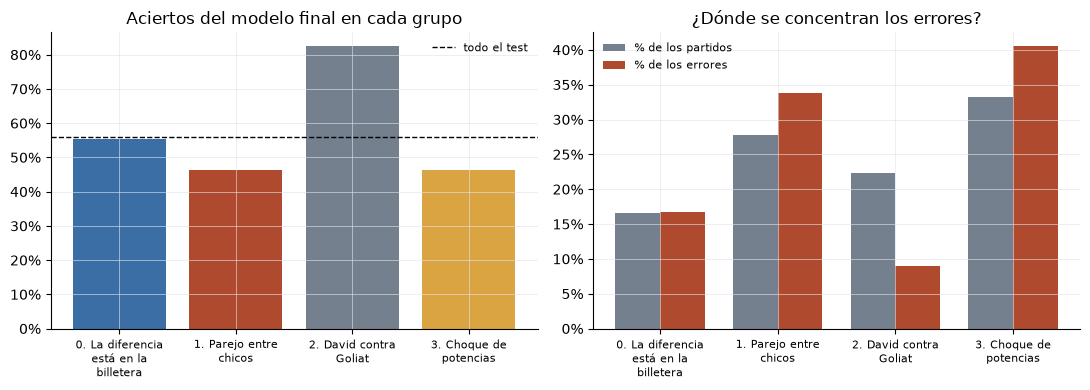

In [19]:
import textwrap
from matplotlib.ticker import PercentFormatter

# los grupos de la seccion 7 contra las predicciones de test de la seccion 6.
# no se ajusta nada nuevo: el agrupador viene del train y las predicciones son las del modelo final
NOMBRES_GRUPOS = {0: "La diferencia está en la billetera", 1: "Parejo entre chicos",
                  2: "David contra Goliat", 3: "Choque de potencias"}

cruce = evaluacion.assign(grupo=grupo_te)
# log-loss de cada partido: que tan poca probabilidad le dio el modelo a lo que de verdad paso
col_real = pd.Index(final_ajustado.classes_).get_indexer(cruce["resultado"])
cruce["perdida"] = -np.log(proba_te[np.arange(len(cruce)), col_real])


def medir(s):
    return {"partidos": len(s),
            "acierto": s["acierto"].mean(),
            "f1_macro": f1_score(s["resultado"], s["pred"], average="macro", zero_division=0),
            "f1_empate": f1_score(s["resultado"], s["pred"], labels=["empate"], average="macro",
                                  zero_division=0),
            "log_loss": s["perdida"].mean(),
            "empates_reales": (s["resultado"] == "empate").mean(),
            "empates_pred": (s["pred"] == "empate").mean(),
            "parte_errores": (~s["acierto"]).sum() / (~cruce["acierto"]).sum()}


por_grupo = pd.DataFrame({g: medir(s) for g, s in cruce.groupby("grupo")}).T
por_grupo["parte_test"] = por_grupo["partidos"] / len(cruce)
por_grupo["parte_train"] = pd.Series(grupo_tr).value_counts(normalize=True)
total = medir(cruce)

titulo("EL MODELO FINAL EN CADA GRUPO (test, 2022–2025)")
print(f"  {'grupo':<38} {'partidos':>9} {'acierto':>8} {'F1 macro':>9} {'F1 empate':>10} {'log-loss':>9}")
for g, f in por_grupo.iterrows():
    print(f"  {g} {NOMBRES_GRUPOS[g]:<36} {f['partidos']:>9,.0f} {f['acierto']:>8.1%} "
          f"{f['f1_macro']:>9.3f} {f['f1_empate']:>10.3f} {f['log_loss']:>9.3f}")
print(f"  {'todo el test':<38} {total['partidos']:>9,} {total['acierto']:>8.1%} "
      f"{total['f1_macro']:>9.3f} {total['f1_empate']:>10.3f} {total['log_loss']:>9.3f}")

titulo("¿DÓNDE SE CONCENTRAN LOS ERRORES Y LOS EMPATES? (test)")
print(f"  {'grupo':<38} {'% partidos':>11} {'% errores':>10} {'empates reales':>15} {'empates pred.':>14}")
for g, f in por_grupo.iterrows():
    print(f"  {g} {NOMBRES_GRUPOS[g]:<36} {f['parte_test']:>11.1%} {f['parte_errores']:>10.1%} "
          f"{f['empates_reales']:>15.1%} {f['empates_pred']:>14.1%}")

# si el test tuviera muchos mas partidos de un grupo dificil, el F1 de test bajaria sin que
# el modelo fuera peor; por eso se compara el reparto
titulo("¿EL TEST SE PARECE AL TRAIN? (reparto de partidos por grupo)")
for g, f in por_grupo.iterrows():
    print(f"  {g} {NOMBRES_GRUPOS[g]:<36} train {f['parte_train']:>6.1%}   test {f['parte_test']:>6.1%}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(K)
etiquetas = [textwrap.fill(f"{g}. {NOMBRES_GRUPOS[g]}", 16) for g in range(K)]
ejes[0].bar(x, por_grupo["acierto"], color=[colores[g] for g in range(K)])
ejes[0].axhline(total["acierto"], color="black", lw=1, ls="--", label="todo el test")
ejes[0].set_title("Aciertos del modelo final en cada grupo")
ejes[0].legend(frameon=False, fontsize=8)
ancho = 0.38
ejes[1].bar(x - ancho / 2, por_grupo["parte_test"], ancho, color=GRIS, label="% de los partidos")
ejes[1].bar(x + ancho / 2, por_grupo["parte_errores"], ancho, color=ROJO, label="% de los errores")
ejes[1].set_title("¿Dónde se concentran los errores?")
ejes[1].legend(frameon=False, fontsize=8)
for ax in ejes:
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas, fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    eje_limpio(ax)
plt.tight_layout()
plt.show()

**Lo que aprendimos al cruzar ambas partes:**
- El modelo falla en los partidos parejos, como se esperaba. "Choque de potencias" y "Parejo entre chicos" son el 61% del test pero concentran el 74% de los errores; en ambos acierta apenas el 46%, contra el 82.4% en "David contra Goliat".

- Los empates fallan distinto en cada grupo. En "David contra Goliat" nunca predice empate, aunque ocurren en el 12.9% de los partidos; en "Choque de potencias" predice de más (36.5% contra 27.8% reales).

- El grupo de la billetera confirma la sección 5. Aunque un país es 12 veces más rico que el otro, el modelo sin PIB acierta el 55.3%, igual que en todo el test. El dinero no explica sus errores.

- El test trae más partidos fáciles. "David contra Goliat" pasa del 16% en train al 22% en test, lo que puede explicar en parte por qué el F1 de test (0.513) supera al de validación (0.504).


## 9. Conclusiones y límites

*Tres párrafos cortos:*

1. **La respuesta a la pregunta de la sección 1, con su número y qué tan seguro es.**
 Sí se puede predecir el resultado de un partido internacional antes de que se juegue, pero solo a medias. El modelo final (boosting sin economía) saca 0.513 de F1 macro en test, contra 0.214 del modelo tonto, y acierta el 55.8% de los partidos contra el 47.4% de decir siempre "gana el local". La segunda pregunta tiene una respuesta más clara, una vez que se conoce el Elo de los dos equipos, el PIB per cápita y la población no agregan nada. En validación mejoran el F1 macro apenas +0.0015, menos que la variación normal entre vueltas (±0.0038), y el log-loss solo baja de 0.947 a 0.943. El resultado es confiable porque las cifras de test se parecen a las de validación y porque la logística y el boosting quedan casi empatados, lo que nos indica que el límite está en la información disponible y no en el modelo. Para una federación que planifica amistosos, lo útil es que la diferencia de Elo dice qué tan predecible es el partido: con más de 400 puntos de diferencia se acierta el 87.8%, y por debajo de 100 apenas entre el 34 y el 37%.

2. **Qué *no* se puede concluir: sesgos del dataset, poblaciones que no aparecen, causas que no se pueden afirmar.**
 Que la economía no agregue nada sobre el Elo no significa que el dinero no importe en el fútbol. Su efecto puede estar ya dentro del rating, acumulado durante décadas, y este análisis no permite separarlos. Además, el 16.5% de los partidos se pierde por falta de datos del Banco Mundial, sobre todo de países pequeños o en conflicto. Las naciones británicas usan el PIB del Reino Unido y los penales cuentan como empate. 

3. **Qué haría falta para mejorarlo.**
 El punto débil son los empates: el modelo solo detecta el 26%. Para mejorar haría falta información que hoy no ve, como la forma reciente de cada equipo o el valor de su plantilla. También se podrían ajustar con validación los parámetros del Elo en lugar de copiarlos de la fórmula, y completar la economía de los países que faltan con otra fuente, como el FMI.

## 10. Lista antes de entregar

- [x] ¿Todo lo que se calcula con los datos está **dentro** del `Pipeline`, y el `Pipeline` dentro de la validación?
- [x] ¿Está escrito **por qué** esa métrica?
- [x] ¿Hay modelo tonto y modelo simple para comparar?
- [x] ¿La búsqueda de opciones dice qué, en qué rango y por qué?
- [x] ¿Cada grupo tiene nombre y descripción en palabras del negocio?
- [x] ¿El test se tocó una sola vez?
- [x] ¿Hay un párrafo de lo que **no** se puede concluir?
- [x] ¿El notebook corre de arriba a abajo sin errores (`Restart & Run All`)?
- [x] ¿Incluye la bitácora de colaboración si usaron AI?

**Entrega: viernes 16 de octubre.** Parcial II: jueves 22 de octubre (sesiones 11 a 21).

## Bitácora de colaboración con AI

Herramienta: Claude Code (modelo Claude Opus 5.5).

| Sección | Qué pidió Milton | Qué hizo la AI | Qué decidió o cambió Milton |
|---|---|---|---|
| Diseño del proyecto | Encontrar cómo darle continuidad al Proyecto 1 para cumplir lo que pide el enunciado. | Propuso y comparó opciones para continuar el P1 contra la rúbrica (mantener el target país-año con un ensamble, o bajar a nivel partido). | Sugirió usar el P1 como base para atacar sus limitantes y sus hallazgos. Planteó el Elo como forma de corregir la fuga de `fuerza_rival` que el P1 declaró como limitante|
| Armado del notebook | Previsualizar la lógica de lo que quería construir, antes de escribirlo: una fila por partido, Elo antes del partido, corte por fecha, `Pipeline` dentro de la validación, tonto y logística, boosting, y la comparación con y sin economía. | Ordenó ese plan en el recorrido de las secciones y ayudó con partes del código cuando la celda ya estaba planteada. | Armó la estructura del notebook y escribió la mayoría de las celdas. La previsualización sirvió para confirmar el plan; los cambios de la AI se aceptaron solo cuando coincidían con lo que ya había decidido. |
| Celdas de respuesta escrita | Aplicar formato markdown a las celdas de respuesta escrita, en especial a las tablas. | Dio formato markdown (tablas, negritas y listas) al texto, sin cambiar el contenido. | Escribió el contenido de esas celdas. |
| 1 · celda del Elo | Revisar su versión de la celda del Elo, que daba `SyntaxError` y cuyos resultados no parecían correctos. | Corrigió el error de sintaxis y revisó la implementación. Ajustó el recorrido para que cada partido use sus propios datos y el rating se acumule de un partido a otro, y que cada fila guarde el Elo de **antes** del partido, para que el resultado no se filtre a las columnas del modelo. También alineó el cálculo del cambio con el resultado real, la diferencia de goles y la ventaja de local, y dejó los valores de K y las categorías de torneo como los de la fórmula del World Football Elo. Se mantuvo la estructura de la celda. Se verificó que las cifras (top 10, Guatemala, tamaño del dataset) coinciden con la versión anterior. | Escribió la primera versión de la celda: la clasificación de torneos, el K por tipo, el multiplicador por goles y el recorrido de los partidos con el valor esperado. Detectó que los resultados no eran razonables y pidió revisarla. |
| 4 · modelo tonto | Revisar el modelo tonto: con `DummyClassifier(strategy="most_frequent")` el log-loss salía infinito. | Cambió la estrategia a `"prior"`. La clase predicha sigue siendo siempre "gana el local", pero `predict_proba` deja de poner 100% al local y 0% a empate y visita, y pasa a usar el reparto de clases del train. Así el log-loss se puede comparar con los otros modelos. | Escribió el `DummyClassifier` dentro del `Pipeline` y la función `validar`. Al correrla vio que el log-loss no servía y pidió el arreglo. |
| 5 · con y sin economía | La celda que compara el mismo modelo con y sin PIB y población no corría: al quitar `dif_log_pib` y `dif_log_pob` del DataFrame, el `ColumnTransformer` pedía esas columnas. | Dejó el DataFrame completo y armó una segunda preparación sin esas dos columnas. La versión sin economía sale de `set_params` sobre una copia del mismo `Pipeline`, con los hiperparámetros que ya había ganado la búsqueda. | Escribió el bucle de la comparación. El error apareció al ejecutar la celda y pidió corregirlo sin cambiar qué se estaba midiendo. |
| 5 · resumen de la búsqueda | El resumen de qué opción pesaba más solo mostraba `class_weight` balanceado. Las combinaciones sin pesos no aparecían. | En pandas 3, `astype(str)` convierte el `None` de `class_weight` en un faltante y `groupby` lo descarta. Lo cambió a `map(str)`, así el grupo sin pesos se queda en la tabla. | Armó la tabla de las mejores combinaciones y el promedio por opción. Notó que faltaba la mitad de `class_weight` y pidió revisarlo. |